# 02 · Exploratory analysis: when, where, who and why

**Question:** Where and when do road collisions happen in Hertfordshire, and what makes them more likely to kill or seriously injure someone?

We look at two measures throughout:
- **Count:** how many collisions. This shows where the *workload* is.
- **KSI rate:** the share of collisions that Killed or Seriously Injured someone. This shows where crashes are most *dangerous*.

Rates come with **95% confidence intervals** (Wilson method). Small groups produce noisy rates, and the intervals stop us over-reading them.

Charts are saved to `report/figures/` for the final report.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN, FIG = ROOT / "data/clean", ROOT / "report/figures"
FIG.mkdir(parents=True, exist_ok=True)

c = pd.read_parquet(CLEAN / "collisions.parquet")
k = pd.read_parquet(CLEAN / "casualties.parquet")
v = pd.read_parquet(CLEAN / "vehicles.parquet")

sns.set_theme(style="whitegrid", context="notebook")
BLUE, RED, GREY = "#2563eb", "#dc2626", "#9ca3af"
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
OVERALL_KSI = c["is_ksi"].mean()

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def ksi_table(df, by, min_n=30):
    """Collisions, KSI count, KSI rate and 95% Wilson CI for each group."""
    t = df.groupby(by, observed=True).agg(collisions=("is_ksi", "size"), ksi=("is_ksi", "sum"))
    t = t[t.collisions >= min_n].copy()
    lo, hi = proportion_confint(t.ksi, t.collisions, method="wilson")
    t["ksi_rate"], t["ci_low"], t["ci_high"] = t.ksi / t.collisions, lo, hi
    return t

def plot_rate(t, title, ax=None, sort=True, color=BLUE, ref=None, unit="collisions"):
    ref = OVERALL_KSI if ref is None else ref
    t = t.sort_values("ksi_rate") if sort else t
    ax = ax or plt.subplots(figsize=(8, 0.45 * len(t) + 1.2))[1]
    y = np.arange(len(t))
    ax.barh(y, t.ksi_rate, color=color, alpha=.85)
    ax.errorbar(t.ksi_rate, y, xerr=[t.ksi_rate - t.ci_low, t.ci_high - t.ksi_rate],
                fmt="none", ecolor="black", capsize=3, lw=1)
    ax.axvline(ref, color=RED, ls="--", lw=1.2, label=f"Herts average {ref:.0%}")
    ax.set_yticks(y, [f"{i}  (n={n:,})" for i, n in zip(t.index, t.collisions)])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set_xlabel(f"Share of {unit} that were KSI"); ax.set_title(title, loc="left", fontweight="bold")
    ax.legend(loc="lower right")
    return ax

print(f"{len(c):,} collisions, {len(k):,} casualties, overall KSI rate {OVERALL_KSI:.1%}")

8,375 collisions, 11,454 casualties, overall KSI rate 20.9%


## 1. Trend over time
Is the problem getting better or worse?

,collisions,ksi,fatal,ksi_rate
year,,,,
2021,1598,342,19,0.214018
2022,1780,363,24,0.203933
2023,1813,386,29,0.212907
2024,1648,315,21,0.191141
2025,1536,348,23,0.226562


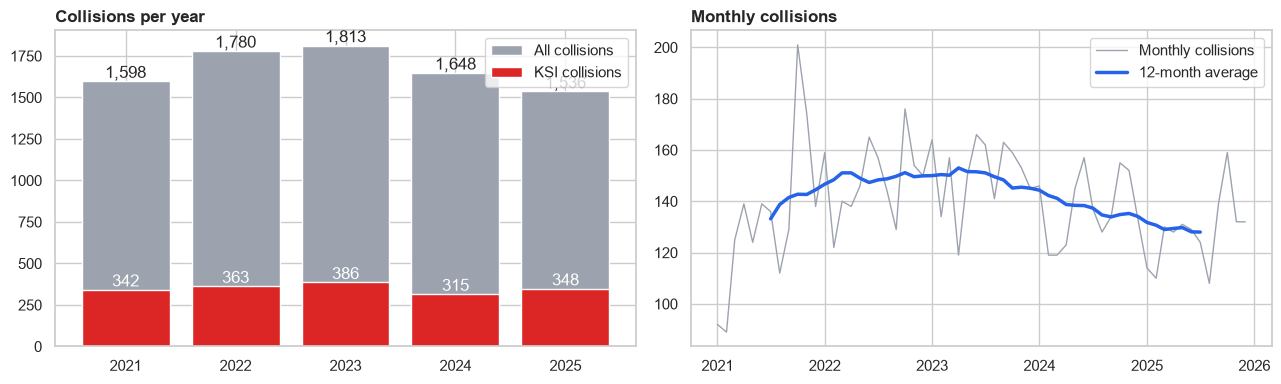

In [2]:
yearly = c.groupby("year").agg(collisions=("is_ksi", "size"), ksi=("is_ksi", "sum"),
                               fatal=("collision_severity", lambda s: (s == 1).sum()))
yearly["ksi_rate"] = yearly.ksi / yearly.collisions

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(yearly.index, yearly.collisions, color=GREY, label="All collisions")
ax[0].bar(yearly.index, yearly.ksi, color=RED, label="KSI collisions")
for x, (n, s) in yearly[["collisions", "ksi"]].iterrows():
    ax[0].text(x, n + 20, f"{n:,}", ha="center"); ax[0].text(x, s + 20, f"{s}", ha="center", color="white" if s > 150 else RED)
ax[0].set_title("Collisions per year", loc="left", fontweight="bold"); ax[0].legend()

monthly = c.set_index("date").resample("MS").agg({"is_ksi": ["size", "sum"]})
monthly.columns = ["collisions", "ksi"]
ax[1].plot(monthly.index, monthly.collisions, color=GREY, lw=1, label="Monthly collisions")
ax[1].plot(monthly.index, monthly.collisions.rolling(12, center=True).mean(), color=BLUE, lw=2.5, label="12-month average")
ax[1].set_title("Monthly collisions", loc="left", fontweight="bold"); ax[1].legend()
plt.tight_layout(); save(fig, "01_trend")
yearly

## 2. When do collisions happen?
### Hour × day of week
The heatmap shows the weekly rhythm. Commuting peaks on weekdays, a different pattern at weekends.

,,collisions
weekday,hour,
Tuesday,17,138
Friday,17,135
Wednesday,8,134
Friday,15,132
Thursday,8,129


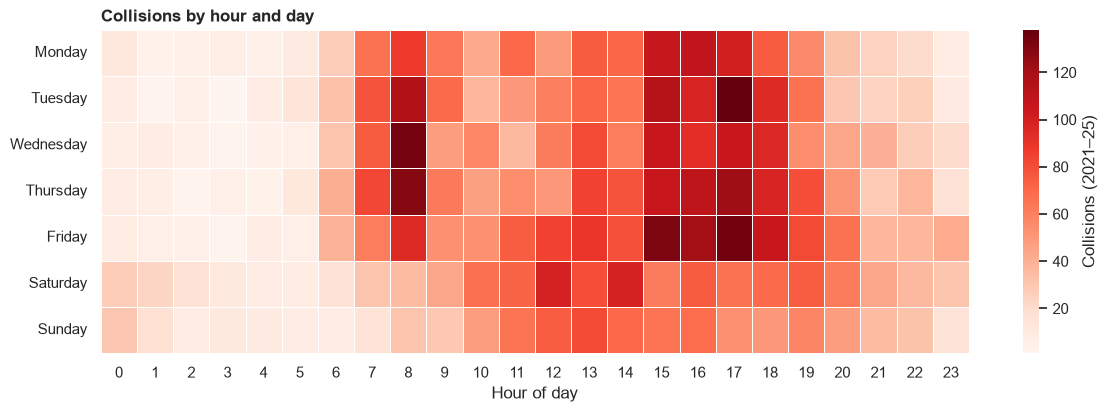

In [3]:
grid = (c.pivot_table(index="weekday", columns="hour", values="collision_index", aggfunc="size")
          .reindex(DAYS).fillna(0))
fig, ax = plt.subplots(figsize=(14, 4.2))
sns.heatmap(grid, cmap="Reds", linewidths=.4, cbar_kws={"label": "Collisions (2021–25)"}, ax=ax)
ax.set_title("Collisions by hour and day", loc="left", fontweight="bold"); ax.set_xlabel("Hour of day"); ax.set_ylabel("")
save(fig, "02_hour_day_heatmap")

peak = grid.stack().sort_values(ascending=False).head(5)
peak.to_frame("collisions")

### Are collisions at some times more *dangerous*?
More traffic means more collisions, but not necessarily worse ones. Night-time crashes are often fewer but more severe.

,collisions,ksi,ksi_rate,ci_low,ci_high
time_band,,,,,
Night (00–05),374,125,33.4%,28.8%,38.4%
Morning peak (06–09),1602,290,18.1%,16.3%,20.1%
Daytime (10–15),3023,609,20.1%,18.8%,21.6%
Evening peak (16–18),1982,390,19.7%,18.0%,21.5%
Evening (19–21),1035,251,24.3%,21.7%,27.0%
Late (22–23),359,89,24.8%,20.6%,29.5%


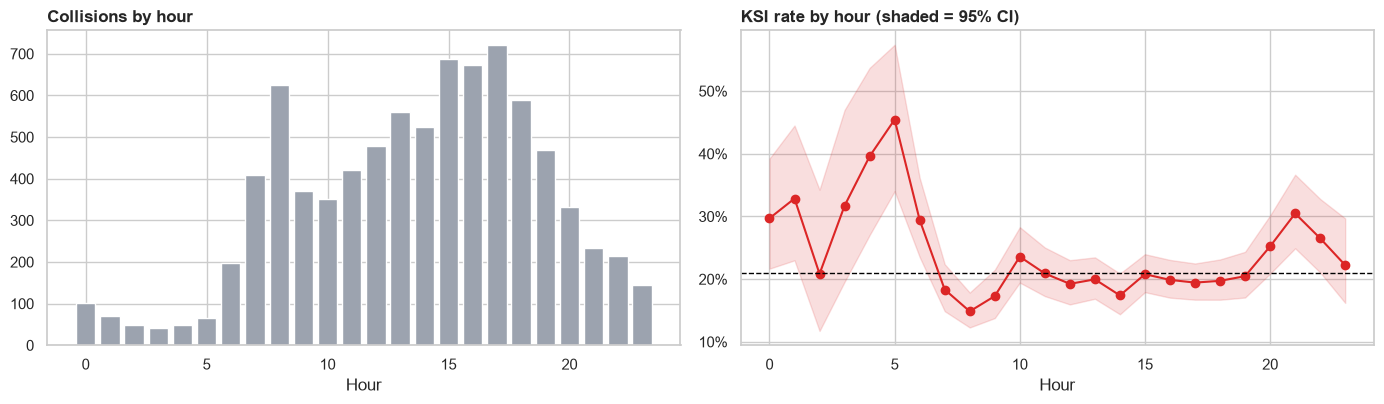

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
hourly = ksi_table(c, "hour", min_n=1)
ax[0].bar(hourly.index, hourly.collisions, color=GREY)
ax[0].set_title("Collisions by hour", loc="left", fontweight="bold"); ax[0].set_xlabel("Hour")
ax[1].plot(hourly.index, hourly.ksi_rate, marker="o", color=RED)
ax[1].fill_between(hourly.index, hourly.ci_low, hourly.ci_high, color=RED, alpha=.15)
ax[1].axhline(OVERALL_KSI, color="black", ls="--", lw=1)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set_title("KSI rate by hour (shaded = 95% CI)", loc="left", fontweight="bold"); ax[1].set_xlabel("Hour")
plt.tight_layout(); save(fig, "03_hourly_severity")

tb = ksi_table(c, "time_band")
tb.style.format({"ksi_rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"})

In [5]:
wk = ksi_table(c.assign(day_type=np.where(c.is_weekend, "Weekend", "Weekday")), "day_type")
month = ksi_table(c, "month_name").reindex(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
display(wk.style.format({"ksi_rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"}))
month[["collisions", "ksi", "ksi_rate"]].style.format({"ksi_rate": "{:.1%}"}).bar(subset=["collisions"], color="#fca5a5")

,collisions,ksi,ksi_rate,ci_low,ci_high
day_type,,,,,
Weekday,6285,1256,20.0%,19.0%,21.0%
Weekend,2090,498,23.8%,22.1%,25.7%


,collisions,ksi,ksi_rate
month_name,,,
Jan,675,105,15.6%
Feb,574,112,19.5%
Mar,671,141,21.0%
Apr,647,159,24.6%
May,696,145,20.8%
Jun,756,160,21.2%
Jul,716,157,21.9%
Aug,633,153,24.2%
Sep,694,143,20.6%


## 3. Where do collisions happen?
### By district: counts vs rates per person
Raw counts favour big districts. To compare fairly we also divide by population (collisions per 10,000 residents per year).

*Population: ONS Census 2021 usual residents, rounded to the nearest 100. Check against [Herts Insight](https://www.hertfordshire.gov.uk/microsites/herts-insight/) before publishing.*

,collisions,ksi,ksi_rate,collisions_per_10k_yr,ksi_per_10k_yr
district,,,,,
Hertsmere,1182,228,19.3%,22.1,4.25
St Albans,1268,254,20.0%,17.0,3.41
North Hertfordshire,845,213,25.2%,12.6,3.19
Welwyn Hatfield,815,184,22.6%,13.6,3.07
Three Rivers,592,128,21.6%,12.6,2.71
East Hertfordshire,917,203,22.1%,12.1,2.69
Dacorum,872,202,23.2%,11.2,2.60
Watford,658,126,19.1%,12.9,2.46
Broxbourne,691,121,17.5%,13.9,2.43


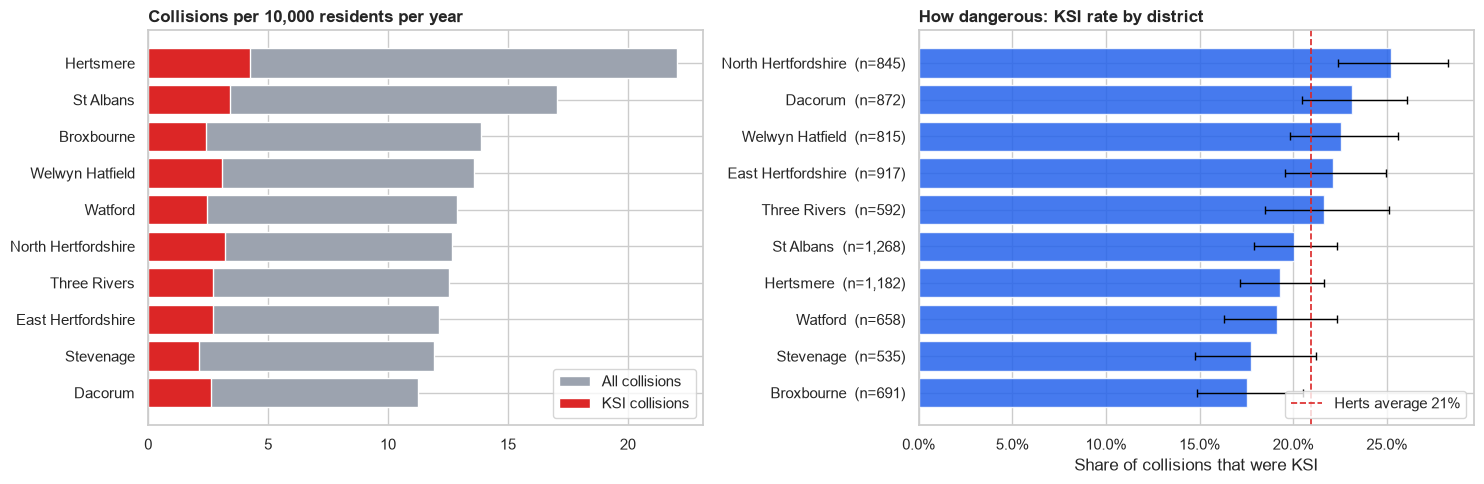

In [6]:
POP_2021 = {"Broxbourne": 99_700, "Dacorum": 155_100, "East Hertfordshire": 151_200, "Hertsmere": 107_200,
            "North Hertfordshire": 133_600, "St Albans": 148_900, "Stevenage": 89_700, "Three Rivers": 94_300,
            "Watford": 102_300, "Welwyn Hatfield": 119_900}
YEARS = c["year"].nunique()

d = ksi_table(c, "district")
d["population"] = d.index.map(POP_2021)
d["collisions_per_10k_yr"] = d.collisions / d.population * 10_000 / YEARS
d["ksi_per_10k_yr"] = d.ksi / d.population * 10_000 / YEARS

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
dd = d.sort_values("collisions_per_10k_yr")
ax[0].barh(dd.index, dd.collisions_per_10k_yr, color=GREY, label="All collisions")
ax[0].barh(dd.index, dd.ksi_per_10k_yr, color=RED, label="KSI collisions")
ax[0].set_title("Collisions per 10,000 residents per year", loc="left", fontweight="bold"); ax[0].legend(loc="lower right")
plot_rate(d, "How dangerous: KSI rate by district", ax=ax[1])
plt.tight_layout(); save(fig, "04_districts")

d[["collisions", "ksi", "ksi_rate", "collisions_per_10k_yr", "ksi_per_10k_yr"]].sort_values("ksi_per_10k_yr", ascending=False)\
  .style.format({"ksi_rate": "{:.1%}", "collisions_per_10k_yr": "{:.1f}", "ksi_per_10k_yr": "{:.2f}"})

> **Caveat:** per-resident rates penalise districts with heavy *through-traffic*. Hertsmere and St Albans carry the M25 and M1, so many people crashing there don't live there. Traffic volume (vehicle-km) would be a better denominator, and the DfT publishes it at local authority level. It's a good extension.

### By type of road

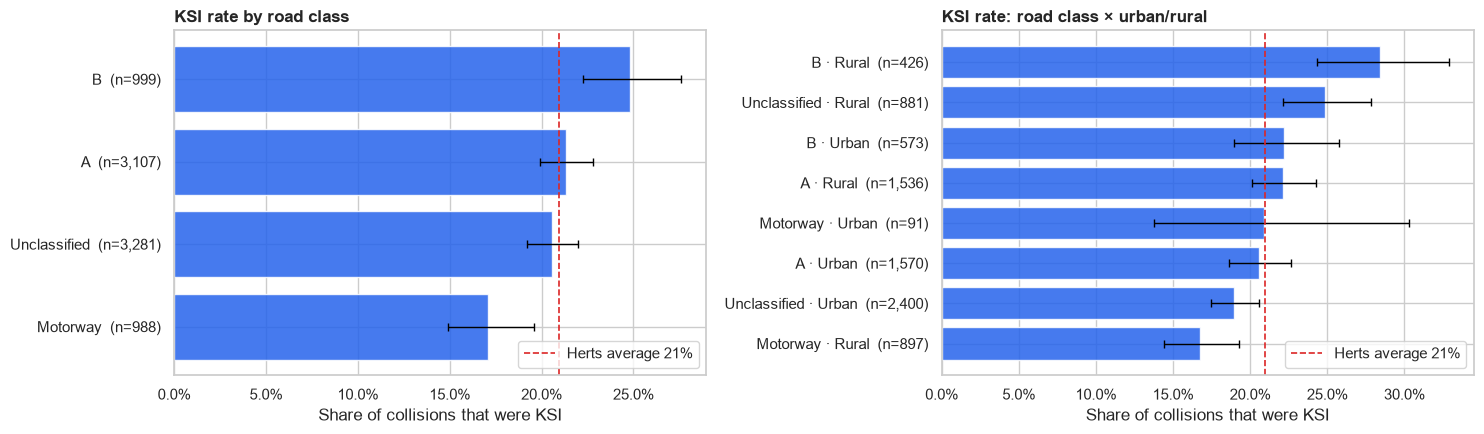

In [7]:
c["road_class"] = c["first_road_class_label"].replace({"A(M)": "Motorway"})
c["road_setting"] = c["road_class"] + " · " + c["urban_or_rural_area_label"]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
plot_rate(ksi_table(c, "road_class"), "KSI rate by road class", ax=ax[0])
plot_rate(ksi_table(c[c.urban_or_rural_area_label != "Unknown"], "road_setting"), "KSI rate: road class × urban/rural", ax=ax[1])
plt.tight_layout(); save(fig, "05_road_class")

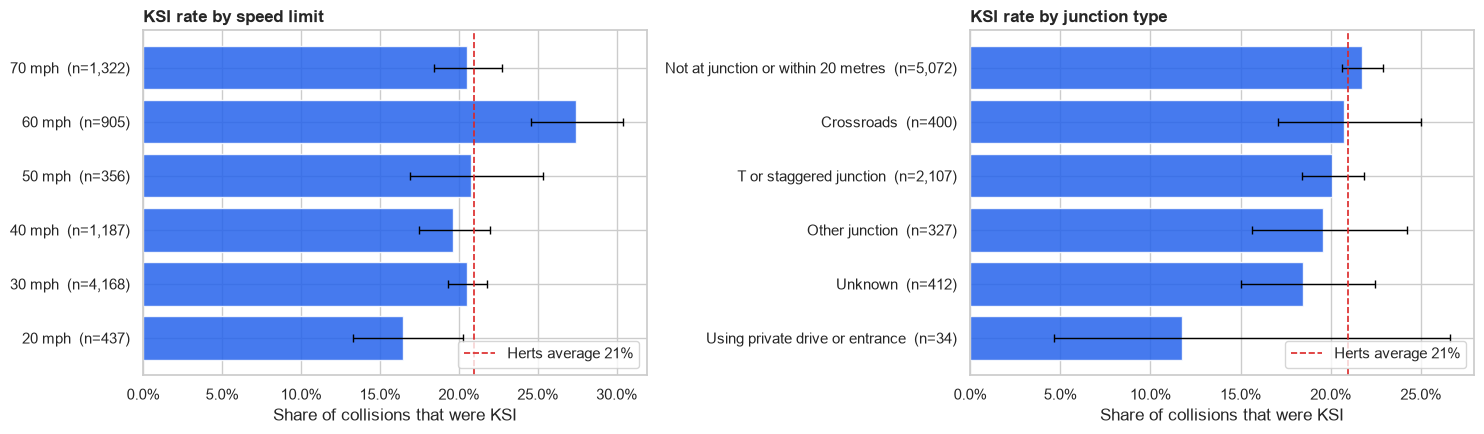

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sl = ksi_table(c.dropna(subset=["speed_limit"]).assign(speed=lambda d: d.speed_limit.astype(int).astype(str) + " mph"), "speed")
sl = sl.loc[sorted(sl.index, key=lambda s: int(s.split()[0]))]
plot_rate(sl, "KSI rate by speed limit", ax=ax[0], sort=False)
plot_rate(ksi_table(c, "junction_detail_label"), "KSI rate by junction type", ax=ax[1])
plt.tight_layout(); save(fig, "06_speed_junction")

### Named roads with the most serious harm
Unclassified (local) roads are left out because they aren't one road. Motorways are kept, though they're run by National Highways rather than the county council.

,collisions,ksi,ksi_rate,ci_low,ci_high
road_name,,,,,
A414,297,64,21.5%,17.3%,26.6%
M1,384,60,15.6%,12.3%,19.6%
M25,389,58,14.9%,11.7%,18.8%
A505,160,53,33.1%,26.3%,40.7%
A1(M),215,51,23.7%,18.5%,29.8%
A10,239,45,18.8%,14.4%,24.3%
A5183,182,43,23.6%,18.0%,30.3%
A602,210,38,18.1%,13.5%,23.9%
A1000,161,36,22.4%,16.6%,29.4%


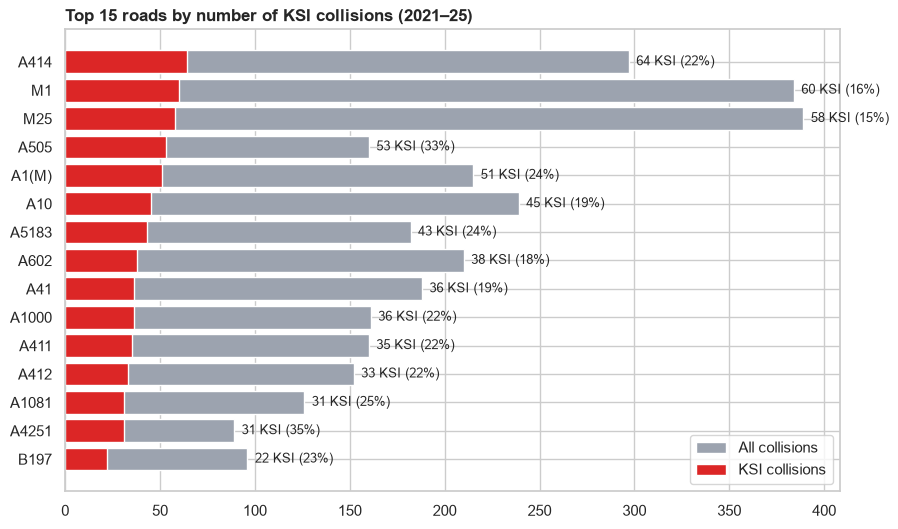

In [9]:
roads = ksi_table(c[~c.road_name.isin(["Unclassified", "Unknown"])], "road_name", min_n=60)
top = roads.sort_values("ksi", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
t = top.sort_values("ksi")
ax.barh(t.index, t.collisions, color=GREY, label="All collisions")
ax.barh(t.index, t.ksi, color=RED, label="KSI collisions")
for i, (n, s, r) in enumerate(t[["collisions", "ksi", "ksi_rate"]].values):
    ax.text(n + 4, i, f"{int(s)} KSI ({r:.0%})", va="center", fontsize=9)
ax.set_title("Top 15 roads by number of KSI collisions (2021–25)", loc="left", fontweight="bold"); ax.legend(loc="lower right")
save(fig, "07_top_roads")
top[["collisions", "ksi", "ksi_rate", "ci_low", "ci_high"]].style.format({"ksi_rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"})

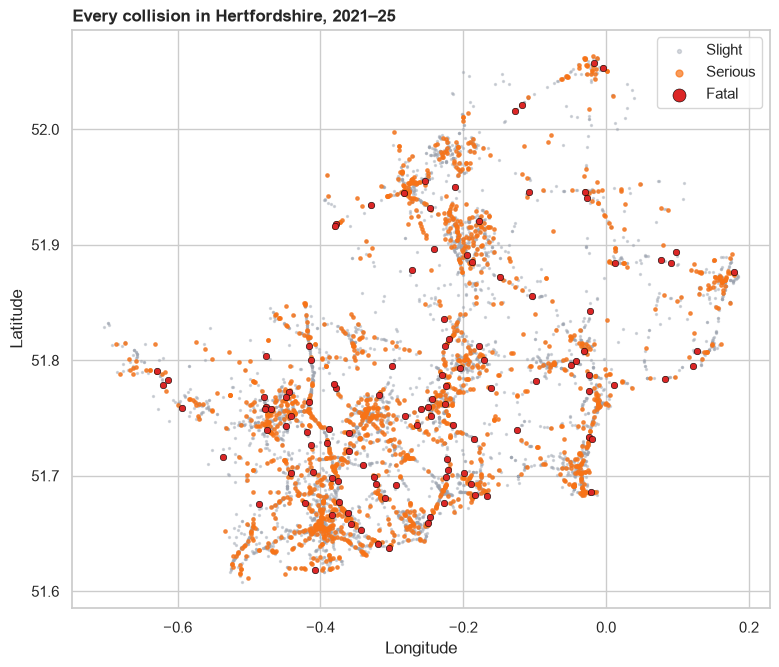

In [10]:
# Quick map preview, a scatter of every collision. The interactive hotspot map comes in notebook 03.
m = c.dropna(subset=["latitude"])
fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(m.longitude, m.latitude, s=2, c=GREY, alpha=.4, label="Slight")
ax.scatter(m[m.collision_severity == 2].longitude, m[m.collision_severity == 2].latitude, s=6, c="#f97316", alpha=.7, label="Serious")
ax.scatter(m[m.collision_severity == 1].longitude, m[m.collision_severity == 1].latitude, s=22, c=RED, edgecolor="black", lw=.4, label="Fatal")
ax.set_aspect(1 / np.cos(np.radians(51.8)))
ax.set_title("Every collision in Hertfordshire, 2021–25", loc="left", fontweight="bold"); ax.legend(markerscale=2)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
save(fig, "08_scatter_map")

## 4. Who gets hurt?
This section is per **casualty**, not per collision. Vulnerable road users (pedestrians, cyclists, motorcyclists) have no protective shell, so their injuries tend to be worse.

,casualties,ksi,ksi_rate,ci_low,ci_high,share_of_all_ksi
casualty_group,,,,,,
E-scooter / PPT user,68,27,39.7%,28.9%,51.6%,1.4%
Motorcyclist,1145,396,34.6%,31.9%,37.4%,20.6%
Other,63,21,33.3%,22.9%,45.6%,1.1%
Pedestrian,1190,369,31.0%,28.4%,33.7%,19.2%
Cyclist,918,244,26.6%,23.8%,29.5%,12.7%
Goods vehicle occupant,535,59,11.0%,8.6%,14.0%,3.1%
Car occupant,7463,799,10.7%,10.0%,11.4%,41.6%
Bus/minibus occupant,72,7,9.7%,4.8%,18.7%,0.4%


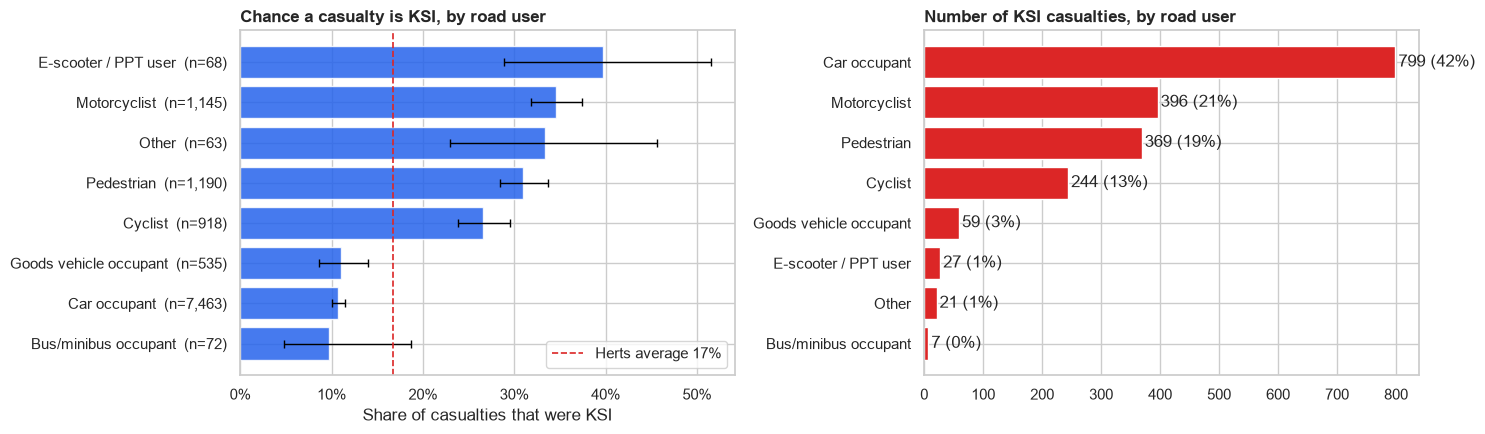

In [11]:
k_ksi = k.assign(collisions=1).groupby("casualty_group").agg(casualties=("is_ksi", "size"), ksi=("is_ksi", "sum"))
lo, hi = proportion_confint(k_ksi.ksi, k_ksi.casualties, method="wilson")
k_ksi["ksi_rate"], k_ksi["ci_low"], k_ksi["ci_high"] = k_ksi.ksi / k_ksi.casualties, lo, hi
k_ksi["share_of_all_ksi"] = k_ksi.ksi / k_ksi.ksi.sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
plot_rate(k_ksi.rename(columns={"casualties": "collisions"}), "Chance a casualty is KSI, by road user", ax=ax[0],
          ref=k.is_ksi.mean(), unit="casualties")
s = k_ksi.sort_values("ksi")
ax[1].barh(s.index, s.ksi, color=RED)
for i, (n, p) in enumerate(s[["ksi", "share_of_all_ksi"]].values):
    ax[1].text(n + 5, i, f"{int(n)} ({p:.0%})", va="center")
ax[1].set_title("Number of KSI casualties, by road user", loc="left", fontweight="bold")
plt.tight_layout(); save(fig, "09_road_users")
k_ksi.sort_values("ksi_rate", ascending=False).style.format({c: "{:.1%}" for c in ["ksi_rate", "ci_low", "ci_high", "share_of_all_ksi"]})

casualty_group,Car occupant,Pedestrian,Cyclist,Motorcyclist
age_band,,,,
0–15,427.0,257.0,106.0,9.0
16–24,1317.0,153.0,123.0,293.0
25–39,2323.0,218.0,202.0,500.0
40–59,2237.0,266.0,338.0,243.0
60–74,665.0,152.0,101.0,68.0
75+,315.0,106.0,18.0,3.0


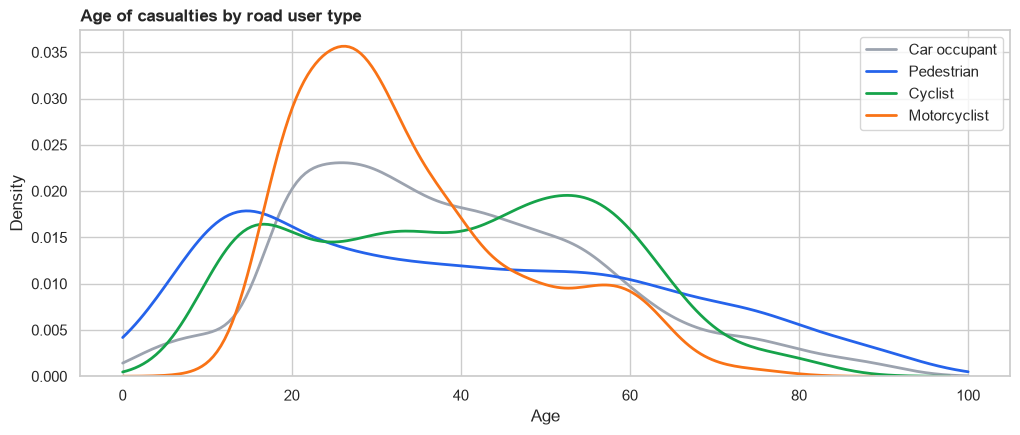

In [12]:
# Age of casualties, split by road user group
ages = k.dropna(subset=["age_of_casualty"])
groups = ["Car occupant", "Pedestrian", "Cyclist", "Motorcyclist"]
fig, ax = plt.subplots(figsize=(12, 4.5))
for g, col in zip(groups, [GREY, BLUE, "#16a34a", "#f97316"]):
    sns.kdeplot(ages[ages.casualty_group == g].age_of_casualty, ax=ax, label=g, color=col, lw=2, clip=(0, 100))
ax.set_title("Age of casualties by road user type", loc="left", fontweight="bold"); ax.set_xlabel("Age"); ax.legend()
save(fig, "10_casualty_age")

ages.assign(age_band=pd.cut(ages.age_of_casualty, [0, 15, 24, 39, 59, 74, 120],
                            labels=["0–15", "16–24", "25–39", "40–59", "60–74", "75+"]))\
    .pivot_table(index="age_band", columns="casualty_group", values="is_ksi", aggfunc="size", observed=True)[groups]

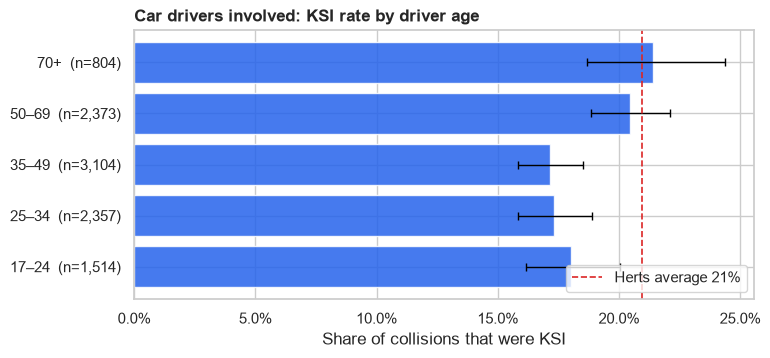

In [13]:
# Drivers: young (17–24) and older (70+) drivers
drv = v.dropna(subset=["age_of_driver"]).query("age_of_driver >= 17 and vehicle_type == 9")  # car drivers
drv = drv.assign(driver_age=pd.cut(drv.age_of_driver, [16, 24, 34, 49, 69, 120], labels=["17–24", "25–34", "35–49", "50–69", "70+"]))
drv = drv.merge(c[["collision_index", "is_ksi"]], on="collision_index")
fig, ax = plt.subplots(figsize=(8, 3.5))
plot_rate(ksi_table(drv, "driver_age"), "Car drivers involved: KSI rate by driver age", ax=ax, sort=False)
save(fig, "11_driver_age")

## 5. Conditions: light, weather, road surface

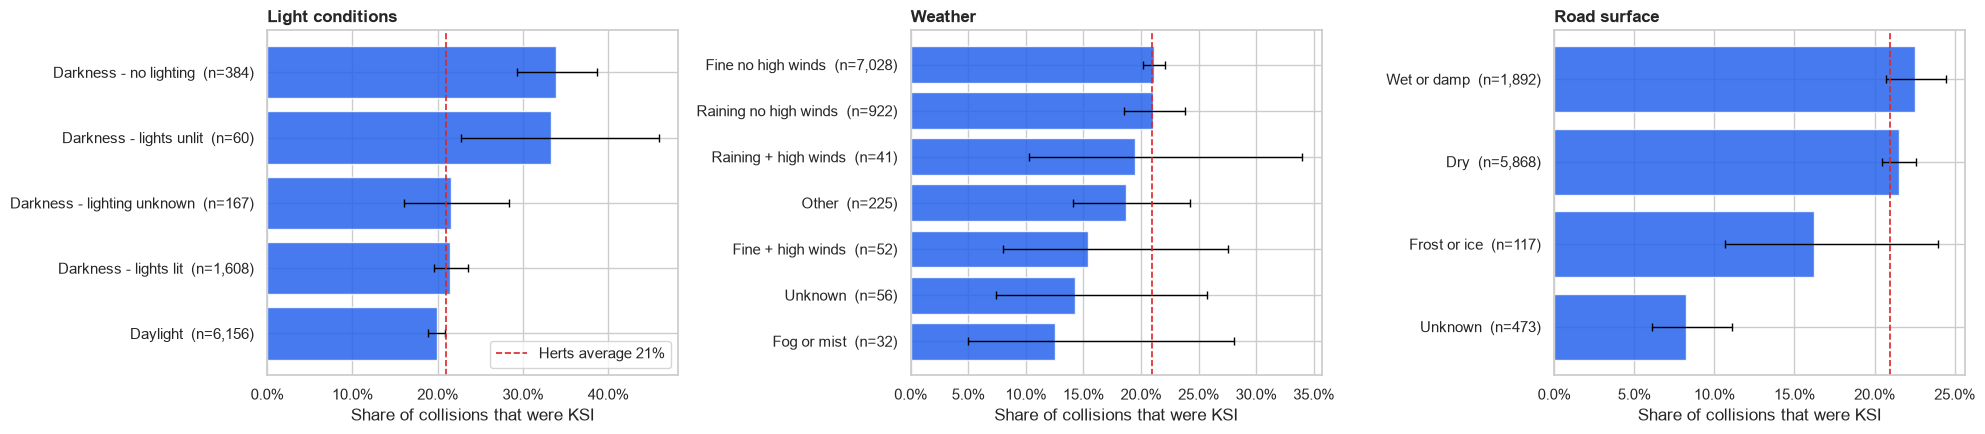

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
plot_rate(ksi_table(c, "light_conditions_label"), "Light conditions", ax=ax[0])
plot_rate(ksi_table(c, "weather_conditions_label"), "Weather", ax=ax[1])
plot_rate(ksi_table(c, "road_surface_conditions_label"), "Road surface", ax=ax[2])
for a in ax[1:]: a.get_legend().remove()
plt.tight_layout(); save(fig, "12_conditions")

### Statistical tests
Are these differences real or just chance? A **chi-square test** checks whether KSI rates differ between groups more than random variation would explain. *p < 0.05* means the difference is unlikely to be chance.

These are **associations, not causes**. For example, rural roads are both darker and faster, so darkness and speed are tangled together. The model in notebook 04 separates these effects.

In [15]:
def chi_test(col, data=c):
    tab = pd.crosstab(data[col], data["is_ksi"])
    chi2, p, dof, _ = chi2_contingency(tab)
    n = tab.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
    return {"variable": col, "chi2": round(chi2, 1), "p_value": p, "cramers_v": round(cramers_v, 3)}

tests = pd.DataFrame([chi_test(x) for x in ["is_dark", "is_urban", "is_junction", "is_weekend", "is_wet_or_icy",
                                             "is_bad_weather", "road_class", "speed_limit", "time_band", "district",
                                             "vulnerable_user_hurt", "involves_motorcycle", "involves_hgv"]])
tests["significant"] = tests.p_value < 0.05
tests["p_value"] = tests.p_value.map(lambda p: f"{p:.1e}")
tests.sort_values("cramers_v", ascending=False).reset_index(drop=True)

,variable,chi2,p_value,cramers_v,significant
0,vulnerable_user_hurt,326.7,5.0e-73,0.198,True
1,involves_motorcycle,142.2,8.9e-33,0.130,True
2,time_band,56.1,7.7e-11,0.082,True
3,speed_limit,29.9,1.5e-05,0.060,True
4,district,26.2,1.9e-03,0.056,True
5,road_class,18.5,3.5e-04,0.047,True
6,is_dark,16.0,6.3e-05,0.044,True
7,is_weekend,13.8,2.1e-04,0.041,True
8,is_urban,6.2,1.3e-02,0.027,True
9,is_junction,2.7,1.0e-01,0.018,False


**Cramér's V** shows how strong a link is (0 = none, 0.1 = weak, 0.3 = moderate). With 8,000+ rows even small effects come out "significant", so V is the more useful number.

## 6. Key findings (computed from the data above)

In [16]:
dark = ksi_table(c, "is_dark"); rural = ksi_table(c, "is_urban"); mc = ksi_table(c, "involves_motorcycle")
vu_ksi = k_ksi.loc[["Pedestrian", "Cyclist", "Motorcyclist"], "ksi"].sum() / k_ksi.ksi.sum()
night = tb.loc["Night (00–05)", "ksi_rate"]
findings = [
    f"Collisions: {len(c):,} in 2021–25 ({yearly.collisions.min():,}–{yearly.collisions.max():,} a year); KSI rate {OVERALL_KSI:.1%}.",
    f"Busiest time: {peak.index[0][0]} {peak.index[0][1]}:00. Weekday commuting peaks dominate the counts.",
    f"Most dangerous time: Night (00–05), KSI rate {night:.0%} vs {OVERALL_KSI:.0%} average.",
    f"Darkness: KSI rate {dark.loc[True, 'ksi_rate']:.0%} in the dark vs {dark.loc[False, 'ksi_rate']:.0%} in daylight.",
    f"Rural roads: KSI rate {rural.loc[False, 'ksi_rate']:.0%} vs urban {rural.loc[True, 'ksi_rate']:.0%}.",
    f"Motorcycles: {mc.loc[True, 'ksi_rate']:.0%} of motorcycle collisions are KSI vs {mc.loc[False, 'ksi_rate']:.0%} otherwise.",
    f"Vulnerable road users (pedestrians, cyclists, motorcyclists) make up {vu_ksi:.0%} of KSI casualties "
    f"but {k_ksi.loc[['Pedestrian','Cyclist','Motorcyclist'],'casualties'].sum()/k_ksi.casualties.sum():.0%} of all casualties.",
    f"Highest KSI per resident: {d.ksi_per_10k_yr.idxmax()} ({d.ksi_per_10k_yr.max():.2f} per 10k/yr); "
    f"lowest: {d.ksi_per_10k_yr.idxmin()} ({d.ksi_per_10k_yr.min():.2f}).",
    f"Roads with most KSI: " + ", ".join(f"{r} ({int(n)})" for r, n in top.ksi.head(5).items()) + ".",
]
for f in findings: print("•", f)
(ROOT / "report").mkdir(exist_ok=True)
(ROOT / "report/eda_findings.md").write_text("# EDA key findings\n\n" + "\n".join(f"- {f}" for f in findings) + "\n")

• Collisions: 8,375 in 2021–25 (1,536–1,813 a year); KSI rate 20.9%.
• Busiest time: Tuesday 17:00. Weekday commuting peaks dominate the counts.
• Most dangerous time: Night (00–05), KSI rate 33% vs 21% average.
• Darkness: KSI rate 24% in the dark vs 20% in daylight.
• Rural roads: KSI rate 22% vs urban 20%.
• Motorcycles: 34% of motorcycle collisions are KSI vs 19% otherwise.
• Vulnerable road users (pedestrians, cyclists, motorcyclists) make up 52% of KSI casualties but 28% of all casualties.
• Highest KSI per resident: Hertsmere (4.25 per 10k/yr); lowest: Stevenage (2.12).
• Roads with most KSI: A414 (64), M1 (60), M25 (58), A505 (53), A1(M) (51).


680

**Next:** `03_hotspots.ipynb`. It finds the exact stretches of road where serious collisions cluster (DBSCAN plus Getis-Ord Gi\* hotspot statistics) and draws them on an interactive map.